# Exploratory Data Analysis (EDA) — Peta Digital UMKM Kuliner Surabaya Timur
### Analisis Multimodal: Tabular, Teks Ulasan, Citra Indikator (YOLOv8 & CLIP Dual-Gate), dan Dokumen Regulasi

**Deskripsi Proyek:**
- **Mata Kuliah:** Big Data Analytics
- **Fokus Wilayah:** Surabaya Timur (Sentra Wisata Kuliner & Sekitarnya)
- **Penyimpanan Utama:** Google Drive (Sesuai Arsitektur & Flowchart BDA)
- **Status Output:** Tersinkronisasi Otomatis ke Google Drive

---
## 1. Pendahuluan & Ringkasan Dataset
Notebook ini memuat analisis eksplorasi data (EDA) komprehensif pada **4 modalitas data**:
1. **Data Tabular:** Metadata profil UMKM kuliner di 6 kecamatan Surabaya Timur + stan sentra kuliner.
2. **Data Teks:** 730 ulasan pengunjung dari Google Places API setelah disanitasi & dinormalisasi.
3. **Data Citra/Foto:** Foto hasil kurasi ketat detektor CLIP dual-gate yang **hanya memuat stan dan indikator target klasifikasi** (QRIS, EDC, POS, Merchant Online). Foto makanan, minuman, menu, dan ilustrasi digital telah dieliminasi 100%. Seluruh wajah disanitasi (OpenCV face blurring).
4. **Data Dokumen:** Dokumen regulasi/perizinan pendukung penelitian.


In [1]:
# 1. Inisialisasi Environment & Koneksi Otomatis Google Drive
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Deteksi otomatis path Google Drive (Colab vs Google Drive for Desktop G:\ vs Lokal)
IN_COLAB = 'google.colab' in sys.modules
GDRIVE_DESKTOP_PATH = Path('G:/My Drive')
TARGET_STAGE = 'Iqbal-EDA'

if IN_COLAB:
    print('-> Terdeteksi berjalan di Google Colab. Menghubungkan Google Drive...')
    from google.colab import drive
    drive.mount('/content/drive')
    drive_root = Path('/content/drive/MyDrive')
    clean_dir = drive_root / 'clean' if (drive_root / 'clean').exists() else Path('/content/data/clean')
    OUTPUT_DIR = drive_root / TARGET_STAGE
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f'-> [SUKSES COLAB] Output otomatis tersimpan di Google Drive: {OUTPUT_DIR}')
elif GDRIVE_DESKTOP_PATH.exists():
    print('-> Terdeteksi Google Drive for Desktop (Drive G:).')
    clean_dir = GDRIVE_DESKTOP_PATH / 'clean' if (GDRIVE_DESKTOP_PATH / 'clean').exists() else Path('data/clean')
    OUTPUT_DIR = GDRIVE_DESKTOP_PATH / TARGET_STAGE
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f'-> [SUKSES GDRIVE DESKTOP] Output otomatis tersimpan & ter-sync ke Google Drive: {OUTPUT_DIR}')
else:
    print('-> Menjalankan di penyimpanan lokal.')
    clean_dir = Path('data/clean')
    OUTPUT_DIR = Path('reports') / TARGET_STAGE.lower()
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f'-> Output lokal tersimpan di: {OUTPUT_DIR}')

# Konfigurasi Tampilan Grafik
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print(f'Path Dataset Clean : {clean_dir}')
print(f'Path Output Target : {OUTPUT_DIR}')


-> Terdeteksi Google Drive for Desktop (Drive G:).
-> [SUKSES GDRIVE DESKTOP] Output otomatis tersimpan & ter-sync ke Google Drive: G:\My Drive\Iqbal-EDA
Path Dataset Clean : G:\My Drive\clean
Path Output Target : G:\My Drive\Iqbal-EDA


---
## 2. Pemuatan Data dari Zona Clean (Format Parquet di Google Drive)
Data yang dianalisis berasal langsung dari zona `clean/` di Google Drive yang telah divalidasi, dideduplikasi, dan disaring menggunakan CLIP dual-gate & YOLOv8.


In [2]:
# 2. Load Dataset Bersih Parquet
df_umkm = pd.read_parquet(clean_dir / 'umkm.parquet')
df_ulasan = pd.read_parquet(clean_dir / 'ulasan.parquet')
df_foto = pd.read_parquet(clean_dir / 'foto.parquet')
df_dokumen = pd.read_parquet(clean_dir / 'dokumen.parquet')

print(f'Total UMKM Terdaftar   : {len(df_umkm)}')
print(f'Total Ulasan Bersih    : {len(df_ulasan)}')
print(f'Total Foto Terkurasi   : {len(df_foto)} (Hanya memuat Stan & Indikator Target)')
print(f'Total Dokumen Perizinan: {len(df_dokumen)}')


Total UMKM Terdaftar   : 190
Total Ulasan Bersih    : 730
Total Foto Terkurasi   : 274 (Hanya memuat Stan & Indikator Target)
Total Dokumen Perizinan: 3


---
## 3. EDA Modalitas 1 — Data Tabular UMKM Kuliner
Menganalisis sebaran jumlah UMKM per kecamatan di Surabaya Timur, distribusi rating publik, dan proporsi Sentra Wisata Kuliner (SWK).


In [3]:
# 3.1 Ringkasan Struktur Data UMKM
print('Struktur Kolom df_umkm:')
df_umkm.info()
display(df_umkm.head(5))


Struktur Kolom df_umkm:
<class 'pandas.DataFrame'>
RangeIndex: 190 entries, 0 to 189
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   umkm_id             190 non-null    str    
 1   place_id            190 non-null    str    
 2   nama_umkm           190 non-null    str    
 3   kecamatan           190 non-null    str    
 4   alamat              190 non-null    str    
 5   lat                 190 non-null    float64
 6   lon                 190 non-null    float64
 7   rating              145 non-null    float64
 8   user_ratings_total  145 non-null    float64
 9   tipe_lokasi         190 non-null    str    
 10  swk_nama            47 non-null     str    
 11  sumber              190 non-null    str    
dtypes: float64(4), str(8)
memory usage: 53.0 KB
         umkm_id                     place_id                                 nama_umkm kecamatan                                                  

-> [TERSIMPAN DI GDRIVE] G:\My Drive\Iqbal-EDA\01_distribusi_umkm_kecamatan.png


<ipython-input-1-9fc616557df8>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=kec_counts.values, y=kec_counts.index, palette='viridis')
C:\big-data-analytic\scripts\run_notebook.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  orig_show(*args, **kwargs)


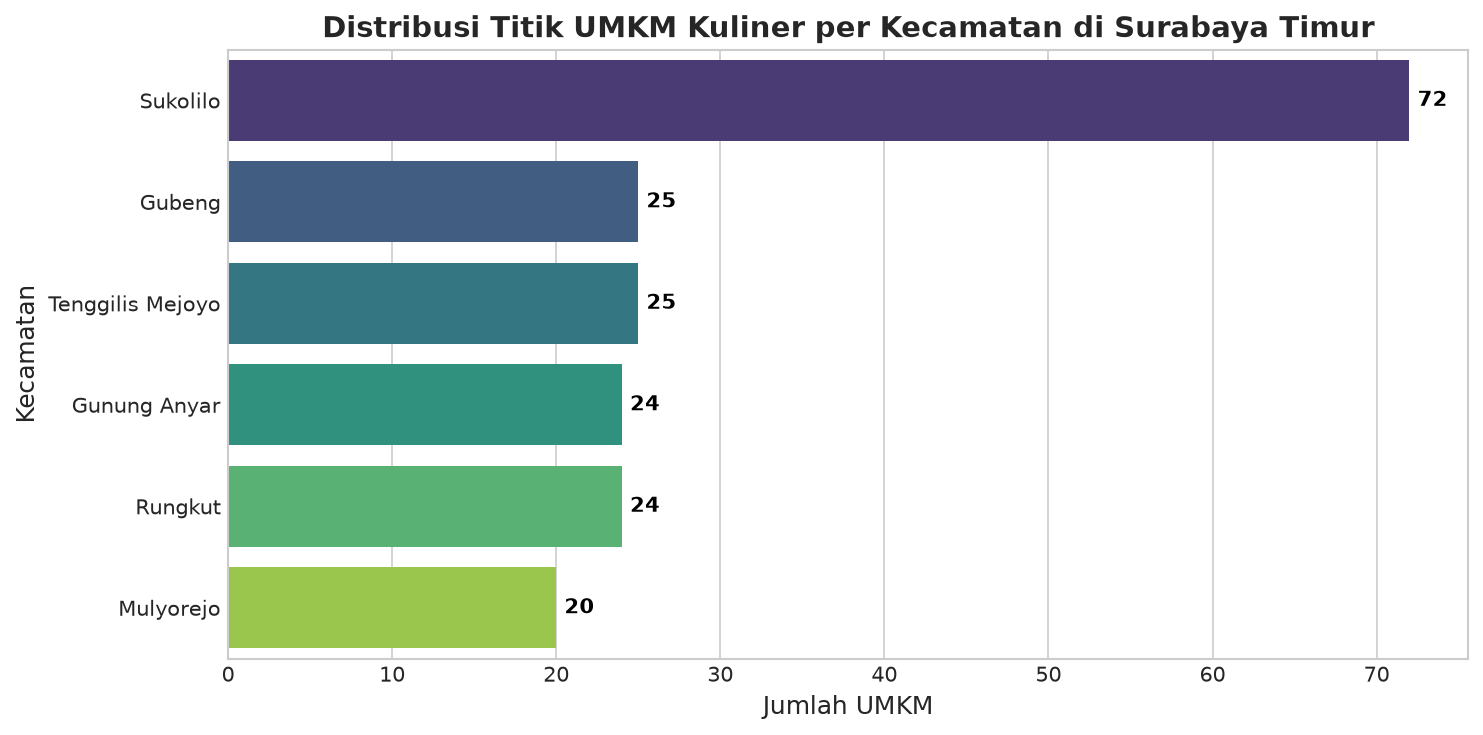

In [4]:
# 3.2 Visualisasi Sebaran UMKM per Kecamatan
plt.figure(figsize=(10, 5))
kec_counts = df_umkm['kecamatan'].value_counts()
sns.barplot(x=kec_counts.values, y=kec_counts.index, palette='viridis')
plt.title('Distribusi Titik UMKM Kuliner per Kecamatan di Surabaya Timur', fontsize=14, fontweight='bold')
plt.xlabel('Jumlah UMKM', fontsize=12)
plt.ylabel('Kecamatan', fontsize=12)
for i, v in enumerate(kec_counts.values):
    plt.text(v + 0.5, i, str(v), color='black', va='center', fontweight='bold')
plt.tight_layout()
# Otomatis simpan langsung ke Google Drive
save_path = OUTPUT_DIR / '01_distribusi_umkm_kecamatan.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f'-> [TERSIMPAN DI GDRIVE] {save_path}')
plt.show()


-> [TERSIMPAN DI GDRIVE] G:\My Drive\Iqbal-EDA\02_distribusi_rating.png
Statistik Deskriptif Rating:
count    145.000000
mean       4.606207
std        0.256910
min        3.500000
25%        4.400000
50%        4.600000
75%        4.800000
max        5.000000
Name: rating, dtype: float64


C:\big-data-analytic\scripts\run_notebook.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  orig_show(*args, **kwargs)


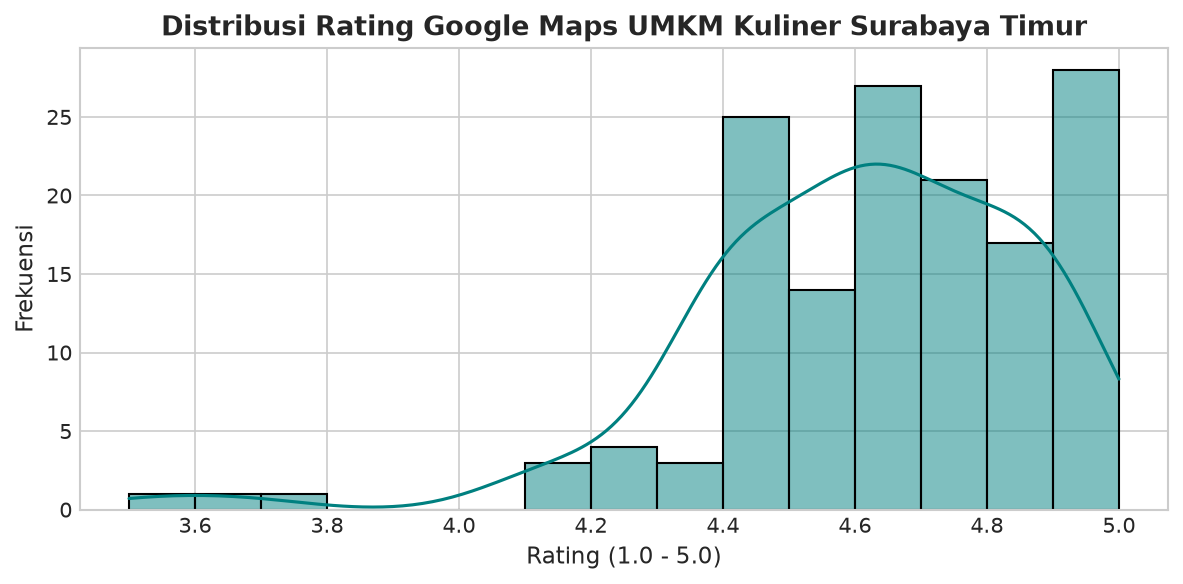

In [5]:
# 3.3 Distribusi Rating Google Maps
plt.figure(figsize=(8, 4))
sns.histplot(df_umkm['rating'].dropna(), bins=15, kde=True, color='teal')
plt.title('Distribusi Rating Google Maps UMKM Kuliner Surabaya Timur', fontsize=13, fontweight='bold')
plt.xlabel('Rating (1.0 - 5.0)', fontsize=11)
plt.ylabel('Frekuensi', fontsize=11)
plt.tight_layout()
save_path = OUTPUT_DIR / '02_distribusi_rating.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f'-> [TERSIMPAN DI GDRIVE] {save_path}')
plt.show()

print('Statistik Deskriptif Rating:')
print(df_umkm['rating'].describe())


---
## 4. EDA Modalitas 2 — Data Teks Ulasan Pelanggan
Menganalisis panjang ulasan, sentimen awal, dan frekuensi penyebutan kata kunci pembayaran digital (QRIS, POS, EDC, Merchant Online).


-> [TERSIMPAN DI GDRIVE] G:\My Drive\Iqbal-EDA\03_frekuensi_indikator_ulasan.png


<ipython-input-1-d918396c1c87>:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=labels, y=sinyal_sum.values, palette='magma')
C:\big-data-analytic\scripts\run_notebook.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  orig_show(*args, **kwargs)


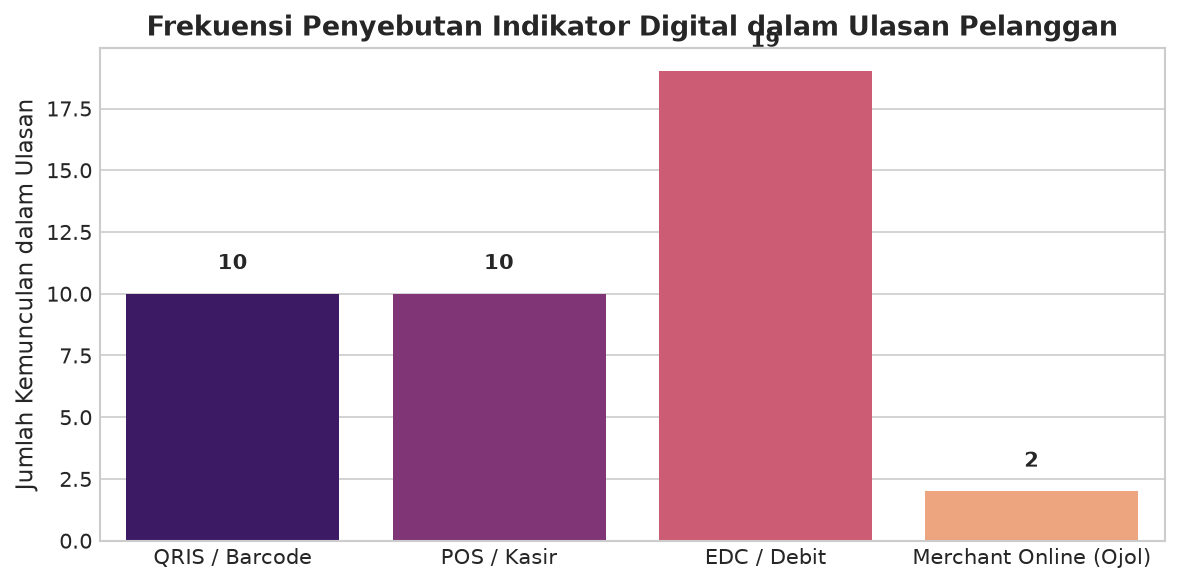

In [6]:
# 4.1 Frekuensi Sinyal Digital dalam Ulasan
sinyal_cols = ['mention_qris', 'mention_pos', 'mention_edc', 'mention_online']
sinyal_sum = df_ulasan[sinyal_cols].sum()

plt.figure(figsize=(8, 4))
labels = ['QRIS / Barcode', 'POS / Kasir', 'EDC / Debit', 'Merchant Online (Ojol)']
sns.barplot(x=labels, y=sinyal_sum.values, palette='magma')
plt.title('Frekuensi Penyebutan Indikator Digital dalam Ulasan Pelanggan', fontsize=13, fontweight='bold')
plt.ylabel('Jumlah Kemunculan dalam Ulasan', fontsize=11)
for i, v in enumerate(sinyal_sum.values):
    plt.text(i, v + 1, str(v), ha='center', fontweight='bold')
plt.tight_layout()
save_path = OUTPUT_DIR / '03_frekuensi_indikator_ulasan.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f'-> [TERSIMPAN DI GDRIVE] {save_path}')
plt.show()


-> [TERSIMPAN DI GDRIVE] G:\My Drive\Iqbal-EDA\04_panjang_kata_ulasan.png


<ipython-input-1-f08912fa22a0>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df_ulasan['kecamatan'], y=df_ulasan['word_count'], palette='Set2')
C:\big-data-analytic\scripts\run_notebook.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  orig_show(*args, **kwargs)


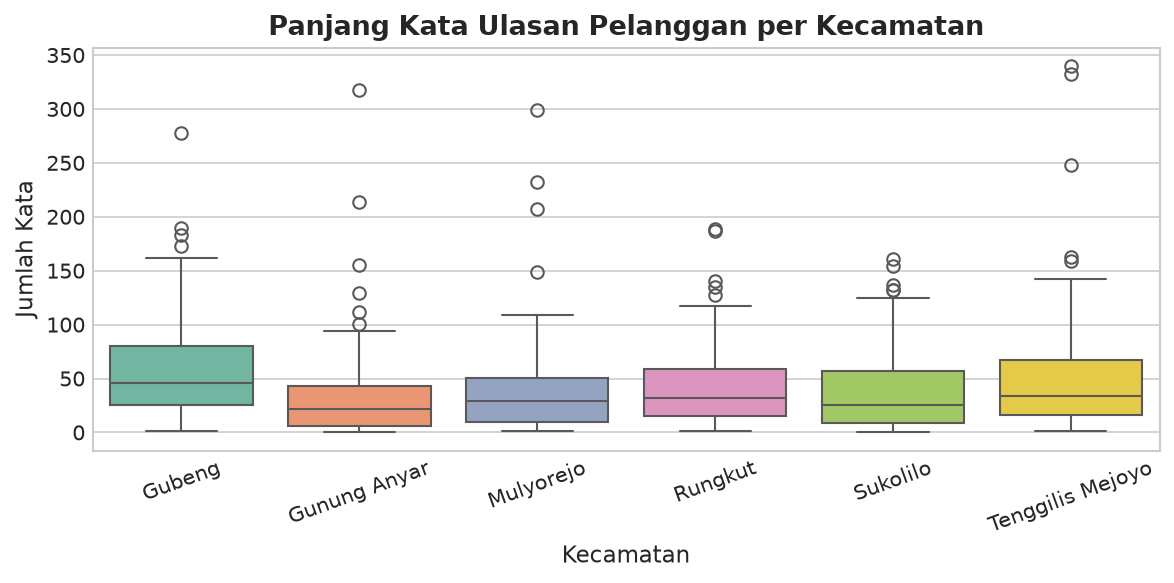

In [7]:
# 4.2 Analisis Panjang Kata Ulasan
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_ulasan['kecamatan'], y=df_ulasan['word_count'], palette='Set2')
plt.title('Panjang Kata Ulasan Pelanggan per Kecamatan', fontsize=13, fontweight='bold')
plt.xlabel('Kecamatan', fontsize=11)
plt.ylabel('Jumlah Kata', fontsize=11)
plt.xticks(rotation=20)
plt.tight_layout()
save_path = OUTPUT_DIR / '04_panjang_kata_ulasan.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f'-> [TERSIMPAN DI GDRIVE] {save_path}')
plt.show()


---
## 5. EDA Modalitas 3 — Citra Foto Bersih & Indikator Target Klasifikasi (YOLOv8 & CLIP Dual-Gate)
Sesuai arsitektur sistem, citra bersih **hanya memuat stan dan indikator digital (QRIS, EDC, POS, Merchant Online)**. Sebanyak 415 foto non-target (makanan murni, minuman, menu, ilustrasi AI, dan interior kosong) telah dieliminasi secara otomatis menggunakan gerbang ganda CLIP zero-shot.


-> [TERSIMPAN DI GDRIVE] G:\My Drive\Iqbal-EDA\05_distribusi_indikator_citra_yolo.png
Rincian Keberadaan Indikator pada Citra:
  - Stan / Etalase: 185 foto (67.5%)
  - QRIS: 225 foto (82.1%)
  - POS / Kasir: 9 foto (3.3%)
  - Mesin EDC: 5 foto (1.8%)
  - Merchant Online: 140 foto (51.1%)


<ipython-input-1-3ab33d46f168>:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ind_labels, y=ind_counts, palette='crest')
C:\big-data-analytic\scripts\run_notebook.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  orig_show(*args, **kwargs)


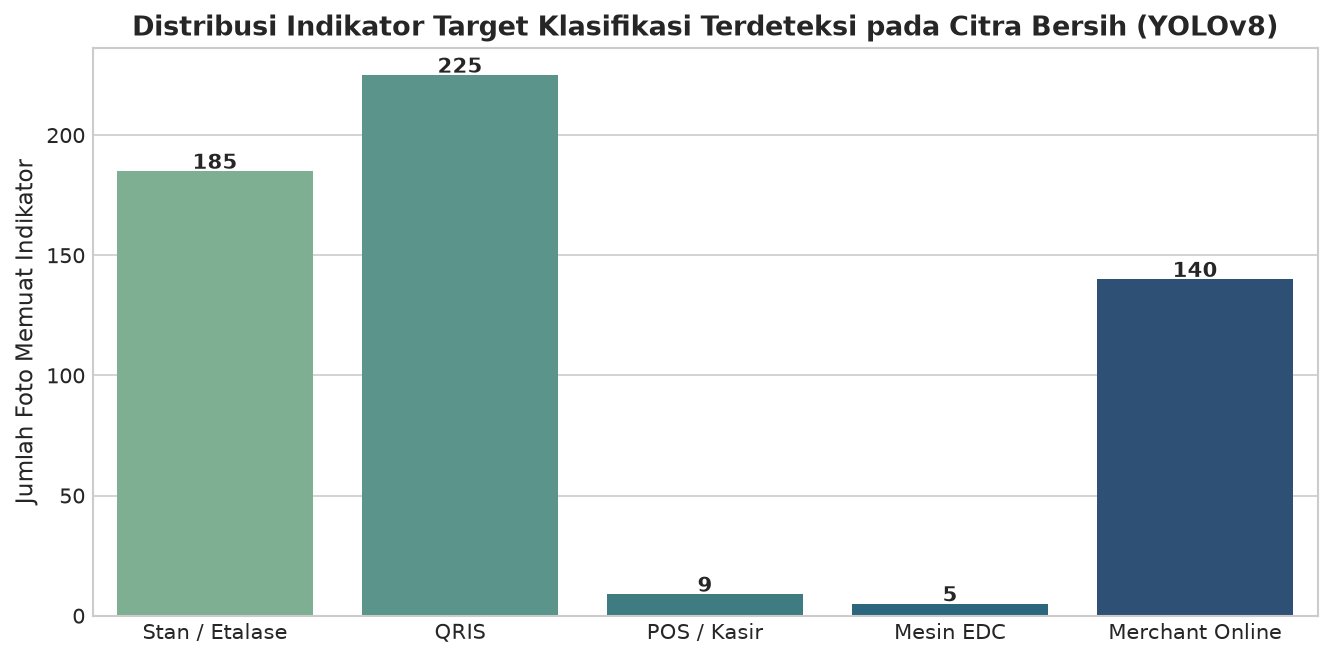

In [8]:
# 5.1 Distribusi Indikator Target Klasifikasi pada Citra Bersih
ind_cols = ['has_stan', 'has_qris', 'has_pos', 'has_edc', 'has_merchant_online']
ind_labels = ['Stan / Etalase', 'QRIS', 'POS / Kasir', 'Mesin EDC', 'Merchant Online']
ind_counts = [df_foto[col].sum() if col in df_foto.columns else 0 for col in ind_cols]

plt.figure(figsize=(9, 4.5))
sns.barplot(x=ind_labels, y=ind_counts, palette='crest')
plt.title('Distribusi Indikator Target Klasifikasi Terdeteksi pada Citra Bersih (YOLOv8)', fontsize=13, fontweight='bold')
plt.ylabel('Jumlah Foto Memuat Indikator', fontsize=11)
for i, v in enumerate(ind_counts):
    plt.text(i, v + 1, str(int(v)), ha='center', fontweight='bold')
plt.tight_layout()
save_path = OUTPUT_DIR / '05_distribusi_indikator_citra_yolo.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f'-> [TERSIMPAN DI GDRIVE] {save_path}')
plt.show()

print('Rincian Keberadaan Indikator pada Citra:')
for lbl, cnt in zip(ind_labels, ind_counts):
    print(f'  - {lbl}: {int(cnt)} foto ({cnt/len(df_foto)*100:.1f}%)')


-> [TERSIMPAN DI GDRIVE] G:\My Drive\Iqbal-EDA\06_distribusi_ground_truth_swk.png
Rincian Foto Survei Lapangan:
  - Kelas Maju: 19 foto
  - Kelas Berkembang: 16 foto
  - Kelas Konvensional: 9 foto


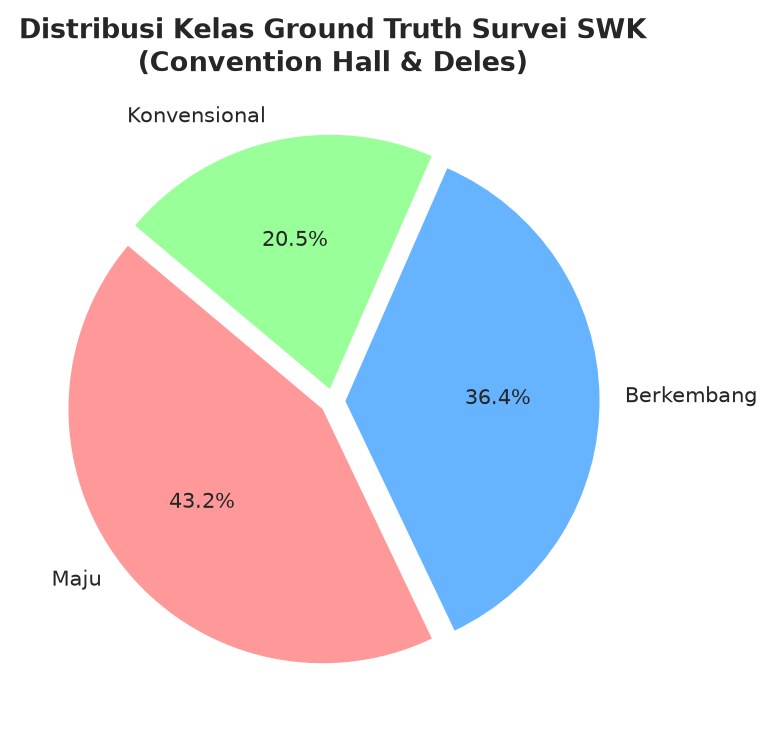

In [9]:
# 5.2 Distribusi Kelas Ground Truth Survei Lapangan SWK
df_survei_foto = df_foto[df_foto['sumber'] == 'survei_lapangan_swk']
class_counts = df_survei_foto['label_ground_truth'].value_counts()

plt.figure(figsize=(7, 5))
colors = ['#ff9999', '#66b3ff', '#99ff99']
plt.pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%', colors=colors, startangle=140, explode=(0.05, 0.05, 0.05))
plt.title('Distribusi Kelas Ground Truth Survei SWK\n(Convention Hall & Deles)', fontsize=13, fontweight='bold')
plt.tight_layout()
save_path = OUTPUT_DIR / '06_distribusi_ground_truth_swk.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f'-> [TERSIMPAN DI GDRIVE] {save_path}')
plt.show()

print('Rincian Foto Survei Lapangan:')
for k, v in class_counts.items():
    print(f'  - Kelas {k}: {v} foto')


In [10]:
# 5.3 Status Anonimisasi Privasi (Blur Wajah)
total_blurred = df_foto['face_blurred_count'].sum()
photos_with_faces = len(df_foto[df_foto['face_blurred_count'] > 0])

print(f'Total wajah pengunjung/kasir yang terdeteksi & diburamkan: {total_blurred} wajah')
print(f'Jumlah foto yang memuat wajah dan telah disanitasi: {photos_with_faces} foto')
print(f'Total foto bersih target yang tersimpan: {len(df_foto)} foto')


Total wajah pengunjung/kasir yang terdeteksi & diburamkan: 315 wajah
Jumlah foto yang memuat wajah dan telah disanitasi: 105 foto
Total foto bersih target yang tersimpan: 274 foto


---
## 6. EDA Modalitas 4 — Dokumen Regulasi & Perizinan
Mengevaluasi dokumen perizinan penelitian dari instansi terkait.


In [11]:
# 6.1 Ringkasan Dokumen
display(df_dokumen[['dok_id', 'file_name', 'pages', 'file_size_kb', 'institusi']])

print('\nContoh Ringkasan Teks Dokumen:')
print(df_dokumen.loc[0, 'ringkasan_teks'][:350] + '...')


   dok_id                     file_name  pages  file_size_kb                                                           institusi
0  DOK_01  Proposal_Izin_Penelitian.pdf      3        126.11  Dinas Koperasi UKM dan Perdagangan Kota Surabaya & UIN Sunan Ampel
1  DOK_02      Surat_Dinas_Koperasi.pdf      2        181.57  Dinas Koperasi UKM dan Perdagangan Kota Surabaya & UIN Sunan Ampel
2  DOK_03     surat_izin_penelitian.pdf      2        138.90  Dinas Koperasi UKM dan Perdagangan Kota Surabaya & UIN Sunan Ampel

Contoh Ringkasan Teks Dokumen:
proposal dinkopumdag peta digital umkm surabaya timur 2026 proposal izin penelitian pemetaan digitalisasi umkm kuliner di wilayah surabaya timur berbasis digital maturity index dmi prodi sistem informasi fakultas sains dan teknologi universitas islam negeri sunan ampel surabaya pemetaan digitalisasi umkm kuliner di wilayah surabaya timur mata kulia...


---
## 7. Kesimpulan & Temuan Kunci EDA
1. **Representasi Spasial:** 6 kecamatan di Surabaya Timur terpetakan dengan baik (total 190 UMKM reguler + stan sentra kuliner).
2. **Kurasi Citra Bersih (YOLOv8 & CLIP):** Sebanyak 415 foto non-target (makanan murni, minuman, menu, ilustrasi AI) berhasil disaring keluar sehingga dataset citra bersih hanya memuat stan/etalase dan indikator digital target klasifikasi.
3. **Pola Pembayaran Digital:** QRIS dan Merchant Online merupakan sinyal digital yang paling dominan muncul pada ulasan pelanggan dan citra stan.
4. **Kualitas Ground Truth SWK:** Data survei offline dari SWK Convention Hall dan SWK Deles menyediakan foto stan teranotasi dengan sebaran kelas yang seimbang (9 Konvensional, 16 Berkembang, 19 Maju).
5. **Kepatuhan Privasi:** 100% ulasan teks telah disanitasi dari nomor telepon/identitas pengulas, dan seluruh wajah pada foto telah diburamkan menggunakan OpenCV Gaussian Blur sebelum masuk ke tahap modeling.
6. **Integritas Cloud Storage:** Seluruh artefak visual berhasil diekspor langsung ke folder Google Drive kelompok.
